In [24]:
%pylab inline
import gc
import os
import smatch
import numpy as np

import pandas as pd
import matplotlib
import astropy.io.fits as pyfits
import matplotlib.pyplot as plt
from astropy.table import Table,join,vstack
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm


import sim_analysis_utilities as utilities

def makePlot(data,ax,scale='linear'):
    weight_data =   np.ones(len(data))

    counts1= np.histogram2d(data['snr'], data['res'], 32, weights=weight_data, range=[[10,80],[0.3,1]], normed=True)[0]
    ax.contour(counts1.T,extent=[10,80,0.3,1],cmap='viridis', levels=[0.01, 0.025, 0.05, 0.075])
    if scale == 'linear':
        im=ax.hist2d(data['snr'], data['res'], 128, weights=weight_data, range=[[10,80],[0.3,1]], cmap='gray_r',normed=True,vmax=0.08,alpha=0.8);
    elif scale=='log':
        im=ax.hist2d(data['snr'], data['res'], 128, weights=weight_data, range=[[10,80],[0.3,1]], cmap='gray_r',normed=True,vmax=0.08,alpha=0.8,norm=LogNorm());
    ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
    ax.set_xlabel('CModel SNR')
    ax.set_ylabel('reGaus resolution')
    plt.colorbar(im[3])
    return ax

Populating the interactive namespace from numpy and matplotlib


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/IPython/core/magics/pylab.py:160: UserWarning: pylab import has clobbered these variables: ['vstack']
`%matplotlib` prevents importing * from pylab and numpy
  "\n`%matplotlib` prevents importing * from pylab and numpy"


# Selection

## Basic Selection

NOT i_deblend_skipped                  AND

NOT i_sdsscentroid_flag                AND

NOT i_pixelflags_edge                  AND

NOT i_pixelflags_interpolatedcenter    AND

NOT i_pixelflags_saturatedcenter       AND

NOT i_pixelflags_crcenter              AND

NOT i_pixelflags_bad                   AND

NOT i_pixelflags_suspectcenter         AND

NOT i_pixelflags_clipped               AND

i_detect_isprimary                     AND

NOT i_hsmshaperegauss_flag       AND

i_extendedness_value != 0              AND

i_hsmshaperegauss_sigma != 'NaN'       AND


## S16A Weak Lensing Selection (AND)
Full Depth Full Color cut              AND

i_cmodel_flux/i_cmodel_fluxerr >10     AND 

i_cmodel_mag<24.5                      AND

log10(i_blendedness_abs)<=-0.375         AND


i_hsmshaperegauss_resolution>0.3       AND


npass>2                                AND


sqrt(i_hsmshaperegauss_e1^2+i_hsmshaperegauss_e2^2)<2.


## S19A Weak Lensing Selection (AND)
i_apertureflux_10_mag<25.5 (corresponding to base_CircularApertureFlux_3_0_instFlux in pipeline)



### Definition of npass
```python
    min_multiband_snr_data  = 5.0
    g_mask  =   (g_snr >= min_multiband_snr_data) & (~np.isnan(g_snr) & (gcountinputs >= 2))
    r_mask  =   (r_snr >= min_multiband_snr_data) & (~np.isnan(r_snr) & (rcountinputs >= 2))
    z_mask  =   (z_snr >= min_multiband_snr_data) & (~np.isnan(z_snr) & (zcountinputs >= 2))
    y_mask  =   (y_snr >= min_multiband_snr_data) & (~np.isnan(y_snr) & (ycountinputs >= 2))
    npass   =   g_mask.astype(int) + r_mask.astype(int) + z_mask.astype(int) + y_mask.astype(int)
```

# All data in S19A FDFC (Full-Deep-Full-Color defined by Hironao) region 

In [2]:
allFname='./wrkDir/database/smallcat-wl-s19-2.fits'
data =   pyfits.getdata(allFname)

In [3]:
"""
# Basic Mask
"""
mask    =   np.ones(len(data),dtype=bool)
mask    &=  (data['npass']>=2)     # npass
mask    &=  (data['logb']<=-0.375) # log(blendedness_abs)
mask    &=  (data['res']>0.3)  # CModel Resolution
mask    &=  (data['snr']>10.)  # CModel SNR
mask    &=  (data['absE']<2.)  # |e| of reGaus ellipticities
mask    &=  (data['mag']<24.5) # Cmodel Magnitude
mask    &=  (data['magA10']<25.5) # 

In [4]:
data1   =   data[mask]

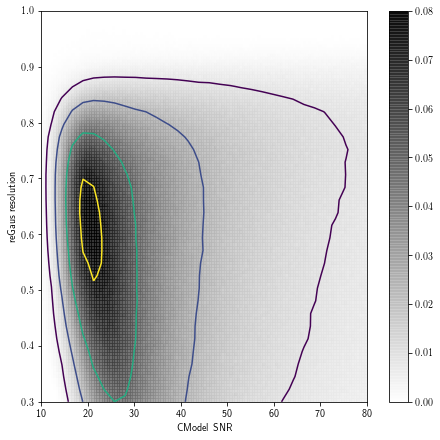

In [39]:
fig1,ax1 = plt.subplots(1,1,figsize=(6, 6),constrained_layout=True)
makePlot(data1,ax1)

# Data in tract 9813 with S19A cut

In [17]:
mask2=mask& (data['tract']==9813)
data2=data[mask2]

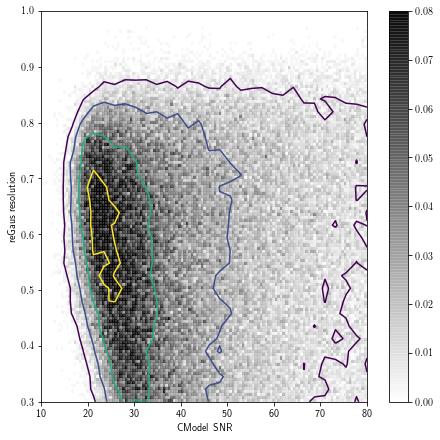

In [40]:
fig2,ax2 = plt.subplots(1,1,figsize=(6, 6),constrained_layout=True)
makePlot(data2,ax2)

# Data in tract 9813 with S18A cut

In [ ]:
testFname='./wrkDir/database/s19-test/tracts/9813.fits'
data2=utilities.make_smallcat_obs(testFname,'nan')
fdfc=utilities.get_FDFC_flag(data2,version='s19')

In [63]:
mask2    =   np.ones(len(data2),dtype=bool)
mask2    &=  (data2['npass']>=2)     # npass
mask2    &=  (data2['logb']<=-0.375) # log(blendedness_abs)
mask2    &=  (data2['res']>0.3)  # CModel Resolution
mask2    &=  (data2['snr']>10.)  # CModel SNR
mask2    &=  (data2['absE']<2.)  # |e| of reGaus ellipticities
mask2    &=  (data2['mag']<24.5) # Cmodel Magnitude
#mask2    &=  (data2['magA10']<25.5) # 
mask2    &=  fdfc

In [64]:
data22=data2[mask2]

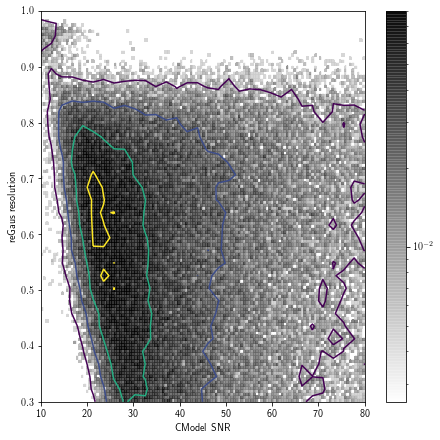

In [65]:
fig3,ax3 = plt.subplots(1,1,figsize=(6, 6),constrained_layout=True)
makePlot(data22,ax3,scale='log')

# Data in tract 9813 with S19A cut but without blendedness cut

In [67]:
mask3    =   np.ones(len(data2),dtype=bool)
mask3    &=  (data2['npass']>=2)     # npass
#mask3    &=  (data2['logb']<=-0.375) # log(blendedness_abs)
mask3    &=  (data2['res']>0.3)  # CModel Resolution
mask3    &=  (data2['snr']>10.)  # CModel SNR
mask3    &=  (data2['absE']<2.)  # |e| of reGaus ellipticities
mask3    &=  (data2['mag']<24.5) # Cmodel Magnitude
mask3    &=  (data2['magA10']<25.5) # 
mask3    &=  fdfc

In [68]:
data23=data2[mask3]

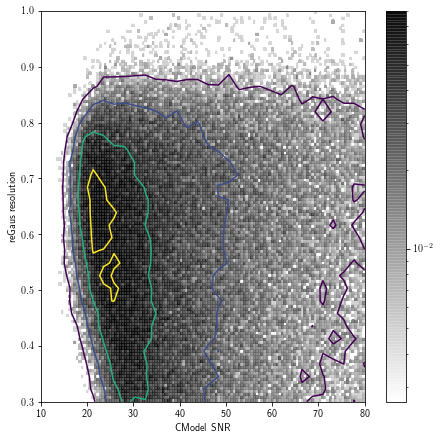

In [69]:
fig4,ax4 = plt.subplots(1,1,figsize=(6, 6),constrained_layout=True)
makePlot(data23,ax4,scale='log')